In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
!pip -q install gdown
!rm -f /content/gate.zip /content/field_test.zip /content/field_new.zip /content/field_holdout_v1.zip /content/citrus_gate_v3.pt
!gdown "1IiL5QoDyr3OZOIIJsGjHFTUrG7Dulj9l" -O /content/gate.zip
!gdown "1Sd6STWIxwxLs3iTJKwaitdBCEMFRH8zk" -O /content/field_test.zip
!gdown "1auQ4r1zXa6EHWzyIcW29i9SGmZfzxMDo" -O /content/field_new.zip
!gdown "1lspyRxtVTyE11pbwOGuMhJ4J2ZPreQ6A" -O /content/field_holdout_v1.zip
!gdown "1sNQLQQl-UF_y0g5Zw8nib6u6kBNRhFbK" -O /content/citrus_gate_v3.pt
!ls -l /content/*.zip /content/*.pt

Downloading...
From (original): https://drive.google.com/uc?id=1IiL5QoDyr3OZOIIJsGjHFTUrG7Dulj9l
From (redirected): https://drive.google.com/uc?id=1IiL5QoDyr3OZOIIJsGjHFTUrG7Dulj9l&confirm=t&uuid=c224db42-4164-4ddd-a7c3-9035fd059ca3
To: /content/gate.zip
100% 91.6M/91.6M [00:00<00:00, 159MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Sd6STWIxwxLs3iTJKwaitdBCEMFRH8zk
To: /content/field_test.zip
100% 10.8M/10.8M [00:00<00:00, 217MB/s]
Downloading...
From: https://drive.google.com/uc?id=1auQ4r1zXa6EHWzyIcW29i9SGmZfzxMDo
To: /content/field_new.zip
100% 15.9M/15.9M [00:00<00:00, 153MB/s]
Downloading...
From: https://drive.google.com/uc?id=1lspyRxtVTyE11pbwOGuMhJ4J2ZPreQ6A
To: /content/field_holdout_v1.zip
100% 2.32M/2.32M [00:00<00:00, 155MB/s]
Downloading...
From: https://drive.google.com/uc?id=1sNQLQQl-UF_y0g5Zw8nib6u6kBNRhFbK
To: /content/citrus_gate_v3.pt
100% 17.0M/17.0M [00:00<00:00, 201MB/s]
-rw-r--r-- 1 root root 252907541 Jul 10  2018 /content/annotations_trainval2017.z

In [ ]:
import os
for p in ("/content/gate_dataset/train/citrus", "/content/gate_dataset/train/not_citrus",
          "/content/exam_v1/citrus", "/content/exam_v2/citrus"):
    print(p, len(os.listdir(p)) if os.path.exists(p) else "MISSING")
coco = sum(f.startswith("coco_") for f in os.listdir("/content/gate_dataset/train/not_citrus")) if os.path.exists("/content/gate_dataset/train/not_citrus") else 0
print("coco files in train:", coco)

/content/gate_dataset/train/citrus 2433
/content/gate_dataset/train/not_citrus 3894
/content/exam_v1/citrus 16
/content/exam_v2/citrus 33
coco files in train: 1050


In [ ]:
import os, shutil
!rm -rf /content/tmp_unzip /content/gate_dataset
!unzip -q /content/gate.zip -d /content/tmp_unzip

for root, dirs, files in os.walk("/content/tmp_unzip"):
    if {"train", "val", "test"} <= set(dirs):
        shutil.move(root, "/content/gate_dataset")
        break

for s in ("train", "val", "test"):
    for c in ("citrus", "not_citrus"):
        print(s, c, len(os.listdir(f"/content/gate_dataset/{s}/{c}")))

train citrus 2081
train not_citrus 2528
val citrus 449
val not_citrus 542
test citrus 442
test not_citrus 541


In [ ]:
import json, random, shutil
!wget -q -nc http://images.cocodataset.org/zips/val2017.zip
!wget -q -nc http://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -q -o val2017.zip
!unzip -q -o annotations_trainval2017.zip annotations/instances_val2017.json

ann = json.load(open("annotations/instances_val2017.json"))
cats = {c["id"]: c["name"] for c in ann["categories"]}
avoid = {"potted plant", "vase", "orange", "apple", "banana", "broccoli", "carrot", "bowl"}
bad = {a["image_id"] for a in ann["annotations"] if cats[a["category_id"]] in avoid}
ids = [i["id"] for i in ann["images"] if i["id"] not in bad]
random.seed(0); random.shuffle(ids)
ids = ids[:1500]

n = len(ids)
cut = {"train": ids[:int(n*.7)], "val": ids[int(n*.7):int(n*.85)], "test": ids[int(n*.85):]}
for split, lst in cut.items():
    for i in lst:
        shutil.copy(f"val2017/{i:012d}.jpg",
                    f"/content/gate_dataset/{split}/not_citrus/coco_{i}.jpg")
    print(split, len(lst))

train 1050
val 225
test 225


In [ ]:
import os, glob, shutil, random
from PIL import Image, ImageOps

REPEAT = 4
TRAIN_ROOT = "/content/gate_dataset"

def find_base(root):
    return [r for r, d, f in os.walk(root) if "citrus" in d][0]

def prep(src, dst):
    im = ImageOps.exif_transpose(Image.open(src)).convert("RGB")
    im.thumbnail((640, 640))
    im.save(dst, quality=90)

for d in ("/content/field_old", "/content/field_new", "/content/_h1", "/content/exam_v1", "/content/exam_v2"):
    shutil.rmtree(d, ignore_errors=True)
!unzip -q /content/field_test.zip -d /content/field_old
!unzip -q /content/field_new.zip -d /content/field_new
!unzip -q /content/field_holdout_v1.zip -d /content/_h1
shutil.copytree(find_base("/content/_h1"), "/content/exam_v1")

for s in ("train", "val"):
    for c in ("citrus", "not_citrus"):
        for f in glob.glob(f"{TRAIN_ROOT}/{s}/{c}/field_*"):
            os.remove(f)

def add_batch(base, tag, seed, hold_dir=None):
    random.seed(seed)
    for cls in ("citrus", "not_citrus"):
        files = sorted(glob.glob(f"{base}/{cls}/*"))
        random.shuffle(files)
        n = len(files); a, b = int(n * .55), int(n * .70)
        parts = {"train": files[:a], "val": files[a:b], "hold": files[b:]}
        for i, f in enumerate(parts["train"]):
            first = f"{TRAIN_ROOT}/train/{cls}/field_{tag}_{i}_0.jpg"
            prep(f, first)
            for r in range(1, REPEAT):
                shutil.copy(first, f"{TRAIN_ROOT}/train/{cls}/field_{tag}_{i}_{r}.jpg")
        for i, f in enumerate(parts["val"]):
            prep(f, f"{TRAIN_ROOT}/val/{cls}/field_{tag}_{i}.jpg")
        if hold_dir:
            os.makedirs(f"{hold_dir}/{cls}", exist_ok=True)
            for i, f in enumerate(parts["hold"]):
                prep(f, f"{hold_dir}/{cls}/{i}.jpg")
        print(tag, cls, {k: len(v) for k, v in parts.items()})

add_batch(find_base("/content/field_old"), "old", 42, hold_dir=None)
add_batch(find_base("/content/field_new"), "new", 7, hold_dir="/content/exam_v2")

for name in ("exam_v1", "exam_v2"):
    for c in ("citrus", "not_citrus"):
        print(name, c, len(os.listdir(f"/content/{name}/{c}")))

old citrus {'train': 28, 'val': 7, 'hold': 16}
old not_citrus {'train': 24, 'val': 7, 'hold': 14}
new citrus {'train': 60, 'val': 17, 'hold': 33}
new not_citrus {'train': 55, 'val': 15, 'hold': 30}
exam_v1 citrus 16
exam_v1 not_citrus 14
exam_v2 citrus 33
exam_v2 not_citrus 30


In [ ]:
import os, glob, random, numpy as np
import torch, torch.nn as nn
from collections import defaultdict
from PIL import Image
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

dev = "cuda" if torch.cuda.is_available() else "cpu"
THR = 0.4
norm = transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = transforms.Compose([transforms.Resize((224,224)), transforms.ToTensor(), norm])

def load_gate(path):
    ck = torch.load(path, map_location=dev)
    m = models.mobilenet_v3_large(weights=None)
    m.classifier[3] = nn.Linear(m.classifier[3].in_features, 2)
    m.load_state_dict(ck["state_dict"])
    return m.to(dev).eval(), ck

def score_dir(m, root, cls):
    m.eval(); out = []
    for f in sorted(glob.glob(f"{root}/{cls}/*")):
        x = tf_eval(Image.open(f).convert("RGB")).unsqueeze(0).to(dev)
        with torch.no_grad():
            out.append((os.path.basename(f), torch.softmax(m(x), 1)[0, 0].item()))
    return out

def exam_report(m, tag, thr=THR):
    res = {}
    for ex in ("exam_v1", "exam_v2"):
        cit = score_dir(m, f"/content/{ex}", "citrus")
        non = score_dir(m, f"/content/{ex}", "not_citrus")
        res[ex] = (cit, non)
        print(f"{tag} {ex}: citrus accepted {sum(p >= thr for _, p in cit)}/{len(cit)}   "
              f"non-citrus accepted {sum(p >= thr for _, p in non)}/{len(non)}")
    cs = np.array([p for ex in res for _, p in res[ex][0]])
    ns = np.array([p for ex in res for _, p in res[ex][1]])
    print(f"{tag} COMBINED at {thr}: citrus {(cs >= thr).sum()}/{len(cs)}, non-citrus {(ns >= thr).sum()}/{len(ns)}")
    print(f"{tag} wrongly accepted:", [(ex, nm, round(p, 2)) for ex in res for nm, p in res[ex][1] if p >= thr])
    print(f"{tag} missed citrus:   ", [(ex, nm, round(p, 2)) for ex in res for nm, p in res[ex][0] if p < thr])
    return res

def thr_table(res, tag):
    cs = np.array([p for ex in res for _, p in res[ex][0]])
    ns = np.array([p for ex in res for _, p in res[ex][1]])
    for t in (0.6, 0.5, 0.4, 0.3, 0.2):
        print(f"  {tag} thr {t}: citrus {(cs >= t).sum()}/{len(cs)}, non-citrus {(ns >= t).sum()}/{len(ns)}")

m3, ck3 = load_gate("/content/citrus_gate_v3.pt")
print(ck3["classes"], "v3 saved threshold:", ck3["threshold"])
res3 = exam_report(m3, "v3")

['citrus', 'not_citrus'] v3 saved threshold: 0.4
v3 exam_v1: citrus accepted 13/16   non-citrus accepted 0/14
v3 exam_v2: citrus accepted 19/33   non-citrus accepted 9/30
v3 COMBINED at 0.4: citrus 32/49, non-citrus 9/44
v3 wrongly accepted: [('exam_v2', '0.jpg', 0.59), ('exam_v2', '15.jpg', 0.51), ('exam_v2', '18.jpg', 0.91), ('exam_v2', '19.jpg', 0.65), ('exam_v2', '24.jpg', 0.6), ('exam_v2', '27.jpg', 0.96), ('exam_v2', '29.jpg', 0.95), ('exam_v2', '3.jpg', 0.64), ('exam_v2', '7.jpg', 0.89)]
v3 missed citrus:    [('exam_v1', '14.jpg', 0.12), ('exam_v1', '2.jpg', 0.16), ('exam_v1', '5.jpg', 0.11), ('exam_v2', '1.jpg', 0.11), ('exam_v2', '10.jpg', 0.07), ('exam_v2', '12.jpg', 0.18), ('exam_v2', '14.jpg', 0.23), ('exam_v2', '15.jpg', 0.38), ('exam_v2', '17.jpg', 0.39), ('exam_v2', '18.jpg', 0.15), ('exam_v2', '2.jpg', 0.23), ('exam_v2', '22.jpg', 0.07), ('exam_v2', '23.jpg', 0.18), ('exam_v2', '25.jpg', 0.2), ('exam_v2', '3.jpg', 0.14), ('exam_v2', '4.jpg', 0.37), ('exam_v2', '6.jpg', 

In [ ]:
import os, torch
p = "/content/citrus_gate_v3.pt"
print(os.path.getsize(p), "bytes   (v3 should be exactly 17025223)")
ck = torch.load(p, map_location="cpu")
print(type(ck))
if isinstance(ck, dict):
    print("keys:", list(ck.keys())[:8])

17025223 bytes   (v3 should be exactly 17025223)
<class 'dict'>
keys: ['state_dict', 'classes', 'threshold']


In [ ]:
random.seed(0); np.random.seed(0); torch.manual_seed(0)

ROOT = "/content/gate_dataset"
tf_train = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.3, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(0.5, 0.5, 0.5, 0.08),
    transforms.RandomGrayscale(0.1),
    transforms.GaussianBlur(5, sigma=(0.1, 1.5)),
    transforms.ToTensor(), norm,
    transforms.RandomErasing(p=0.25),
])

train_ds = datasets.ImageFolder(f"{ROOT}/train", tf_train)
val_ds   = datasets.ImageFolder(f"{ROOT}/val",   tf_eval)
test_ds  = datasets.ImageFolder(f"{ROOT}/test",  tf_eval)
print(train_ds.class_to_idx)
print("train/val/test sizes:", len(train_ds), len(val_ds), len(test_ds))

is_field = np.array([os.path.basename(p).startswith("field_") for p, _ in val_ds.samples])
print("field images in val:", int(is_field.sum()))

mk = lambda ds, sh: DataLoader(ds, batch_size=64, shuffle=sh, num_workers=2)
train_dl, val_dl, test_dl = mk(train_ds, True), mk(val_ds, False), mk(test_ds, False)

counts = np.bincount(train_ds.targets)
w = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32).to(dev)

model = models.mobilenet_v3_large(weights="DEFAULT")
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)
model.to(dev)

EPOCHS = 8
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
loss_fn = nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)

@torch.no_grad()
def p_citrus(dl):
    model.eval(); P, Y = [], []
    for x, y in dl:
        P.append(torch.softmax(model(x.to(dev)), 1)[:, 0].cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

{'citrus': 0, 'not_citrus': 1}
train/val/test sizes: 6327 1262 1208
field images in val: 46
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 178MB/s]


In [ ]:
best = -1
for epoch in range(EPOCHS):
    model.train()
    for x, y in train_dl:
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad(); loss_fn(model(x), y).backward(); opt.step()
    sched.step()
    p, y = p_citrus(val_dl)
    ok = ((p > 0.5) == (y == 0))
    acc_all, acc_field = ok.mean(), ok[is_field].mean()
    print(f"epoch {epoch+1}: val acc {acc_all:.3f}   field-only val acc {acc_field:.3f}", flush=True)
    if acc_all + acc_field > best:
        best = acc_all + acc_field
        torch.save(model.state_dict(), "gate_best.pt")

epoch 1: val acc 0.903   field-only val acc 0.652
epoch 2: val acc 0.971   field-only val acc 0.783
epoch 3: val acc 0.993   field-only val acc 0.891
epoch 4: val acc 0.987   field-only val acc 0.848
epoch 5: val acc 0.993   field-only val acc 0.848
epoch 6: val acc 0.994   field-only val acc 0.870
epoch 7: val acc 0.994   field-only val acc 0.848
epoch 8: val acc 0.994   field-only val acc 0.848


In [ ]:
model.load_state_dict(torch.load("gate_best.pt")); model.eval()
thr = THR

p_t, y_t = p_citrus(test_dl)
accept = p_t >= thr
print("clean test citrus accepted:    ", round(accept[y_t == 0].mean(), 3))
print("clean test non-citrus accepted:", round(accept[y_t == 1].mean(), 3), "(want near 0)")

groups = defaultdict(list)
for (path, label), a in zip(test_ds.samples, accept):
    if label == 1:
        name = os.path.basename(path)
        key = name.split("_")[0] if name.startswith(("imagenette_", "coco_")) else "leaf_negatives"
        groups[key].append(a)
for k, v in groups.items():
    print(f"  {k:15s} wrongly accepted: {np.mean(v):.3f}  (n={len(v)})")

torch.save({"state_dict": model.state_dict(), "classes": train_ds.classes,
            "threshold": thr}, "citrus_gate_v4.pt")
from google.colab import files
files.download("citrus_gate_v4.pt")

clean test citrus accepted:     0.995
clean test non-citrus accepted: 0.008 (want near 0)
  coco            wrongly accepted: 0.004  (n=225)
  imagenette      wrongly accepted: 0.000  (n=60)
  leaf_negatives  wrongly accepted: 0.010  (n=481)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
res4 = exam_report(model, "v4")
print()
thr_table(res3, "v3")
thr_table(res4, "v4")

v4 exam_v1: citrus accepted 15/16   non-citrus accepted 0/14
v4 exam_v2: citrus accepted 29/33   non-citrus accepted 5/30
v4 COMBINED at 0.4: citrus 44/49, non-citrus 5/44
v4 wrongly accepted: [('exam_v2', '1.jpg', 0.43), ('exam_v2', '13.jpg', 0.59), ('exam_v2', '19.jpg', 0.89), ('exam_v2', '24.jpg', 0.88), ('exam_v2', '29.jpg', 0.95)]
v4 missed citrus:    [('exam_v1', '5.jpg', 0.38), ('exam_v2', '12.jpg', 0.23), ('exam_v2', '22.jpg', 0.37), ('exam_v2', '3.jpg', 0.13), ('exam_v2', '6.jpg', 0.4)]

  v3 thr 0.6: citrus 29/49, non-citrus 6/44
  v3 thr 0.5: citrus 30/49, non-citrus 9/44
  v3 thr 0.4: citrus 32/49, non-citrus 9/44
  v3 thr 0.3: citrus 35/49, non-citrus 11/44
  v3 thr 0.2: citrus 39/49, non-citrus 14/44
  v4 thr 0.6: citrus 39/49, non-citrus 3/44
  v4 thr 0.5: citrus 41/49, non-citrus 4/44
  v4 thr 0.4: citrus 44/49, non-citrus 5/44
  v4 thr 0.3: citrus 47/49, non-citrus 8/44
  v4 thr 0.2: citrus 48/49, non-citrus 14/44


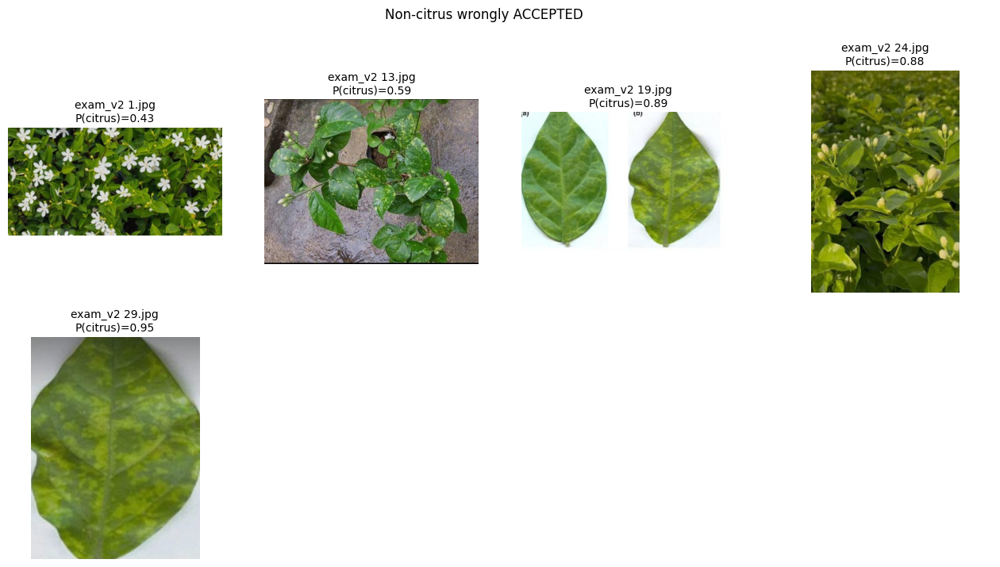

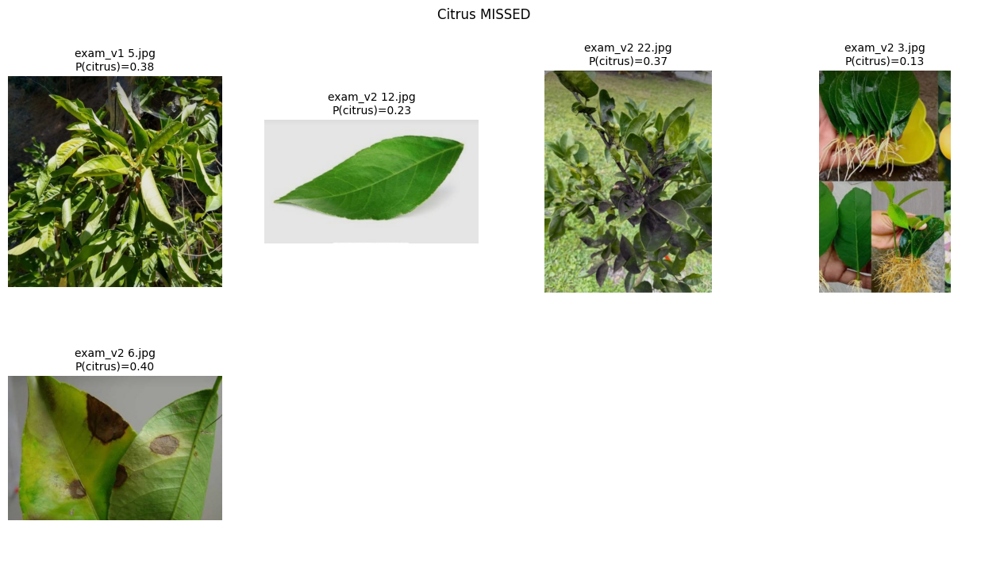

In [ ]:
import matplotlib.pyplot as plt

wrong = [(k, n, p) for k in res4 for n, p in res4[k][1] if p >= THR]
miss  = [(k, n, p) for k in res4 for n, p in res4[k][0] if p < THR]

def show(items, cls, title):
    if not items:
        print(title, ": none"); return
    cols = 4
    rows = (len(items) + cols - 1) // cols
    fig, axs = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs: ax.axis("off")
    for ax, (k, n, p) in zip(axs, items):
        ax.imshow(Image.open(f"/content/{k}/{cls}/{n}"))
        ax.set_title(f"{k} {n}\nP(citrus)={p:.2f}", fontsize=10)
    fig.suptitle(title); plt.show()

show(wrong, "not_citrus", "Non-citrus wrongly ACCEPTED")
show(miss, "citrus", "Citrus MISSED")

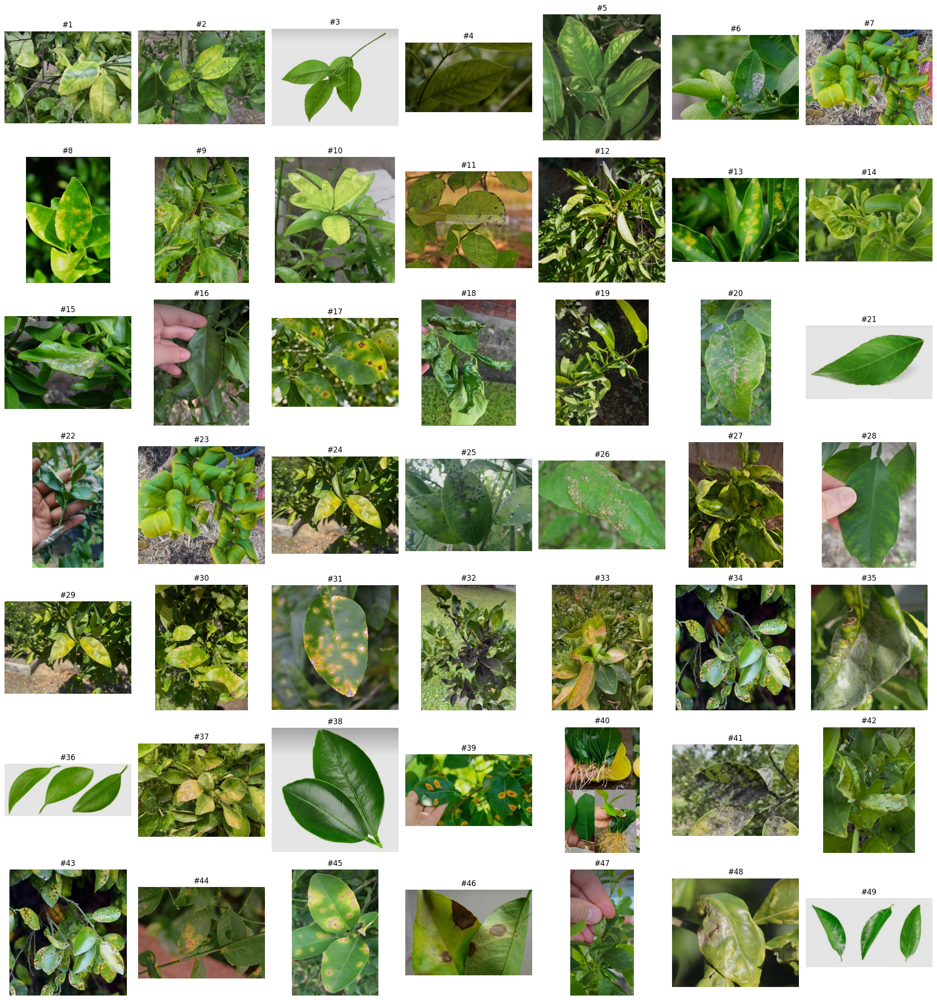

In [ ]:
items = [(k, n) for k in ("exam_v1", "exam_v2") for n, p in res4[k][0]]
cols = 7
rows = (len(items) + cols - 1) // cols
fig, axs = plt.subplots(rows, cols, figsize=(3 * cols, 3.2 * rows))
for ax in axs.ravel(): ax.axis("off")
for i, ((k, n), ax) in enumerate(zip(items, axs.ravel()), 1):
    im = Image.open(f"/content/{k}/citrus/{n}"); im.thumbnail((300, 300))
    ax.imshow(im); ax.set_title(f"#{i}", fontsize=12)
plt.tight_layout(); plt.show()

In [ ]:
OUT = []   # for example [3, 8, 21]
keep = [(k, n) for i, (k, n) in enumerate(items, 1) if i not in OUT]
for tag, res in (("v3", res3), ("v4", res4)):
    pm = {(k, n): p for k in res for n, p in res[k][0]}
    ok = sum(pm[x] >= THR for x in keep)
    print(f"{tag}: in-scope citrus accepted {ok}/{len(keep)}   misses:",
          [(k, n, round(pm[(k, n)], 2)) for k, n in keep if pm[(k, n)] < THR])

v3: in-scope citrus accepted 32/49   misses: [('exam_v1', '14.jpg', 0.12), ('exam_v1', '2.jpg', 0.16), ('exam_v1', '5.jpg', 0.11), ('exam_v2', '1.jpg', 0.11), ('exam_v2', '10.jpg', 0.07), ('exam_v2', '12.jpg', 0.18), ('exam_v2', '14.jpg', 0.23), ('exam_v2', '15.jpg', 0.38), ('exam_v2', '17.jpg', 0.39), ('exam_v2', '18.jpg', 0.15), ('exam_v2', '2.jpg', 0.23), ('exam_v2', '22.jpg', 0.07), ('exam_v2', '23.jpg', 0.18), ('exam_v2', '25.jpg', 0.2), ('exam_v2', '3.jpg', 0.14), ('exam_v2', '4.jpg', 0.37), ('exam_v2', '6.jpg', 0.25)]
v4: in-scope citrus accepted 44/49   misses: [('exam_v1', '5.jpg', 0.38), ('exam_v2', '12.jpg', 0.23), ('exam_v2', '22.jpg', 0.37), ('exam_v2', '3.jpg', 0.13), ('exam_v2', '6.jpg', 0.4)]


In [ ]:
import re
LINES = []
def log(s=""):
    print(s); LINES.append(s)

def source_of(name, cls):
    n = name.lower()
    if n.startswith("coco_"):        return "COCO (people, rooms, objects)"
    if n.startswith("imagenette_"):  return "Imagenette (everyday objects)"
    if n.startswith("phone_"):       return "Phone photos"
    if n.startswith("field_old_"):   return "Field photos, batch 1"
    if n.startswith("field_new_"):   return "Field photos, batch 2"
    if "plantdoc" in n:              return "PlantDoc leaves"
    if "mango" in n:                 return "MangoLeafBD leaves"
    return "Citrus disease dataset" if cls == "citrus" else "Base leaves (PlantDoc + MangoLeafBD)"

def unique_key(name):
    m = re.match(r"(field_(?:old|new)_\d+)(?:_\d+)?\.jpg$", name)
    return m.group(1) if m else name

def summarize(ds, split):
    idx2cls = {v: k for k, v in ds.class_to_idx.items()}
    files, uniq = defaultdict(int), defaultdict(set)
    for path, y in ds.samples:
        name = os.path.basename(path)
        key = (idx2cls[y], source_of(name, idx2cls[y]))
        files[key] += 1
        uniq[key].add(unique_key(name))
    log(f"\n=== {split.upper()} ({len(ds)} files) ===")
    log(f"{'class':12s} {'source':38s} {'files':>7s} {'unique':>7s}")
    for cls in ("citrus", "not_citrus"):
        tf = tu = 0
        for (c, src), n in sorted(files.items()):
            if c == cls:
                u = len(uniq[(c, src)])
                log(f"{c:12s} {src:38s} {n:7d} {u:7d}")
                tf += n; tu += u
        log(f"{cls:12s} {'TOTAL':38s} {tf:7d} {tu:7d}")

log("DATASETS USED TO TRAIN THE CITRUS GATE")
for ds, split in ((train_ds, "train"), (val_ds, "val"), (test_ds, "test")):
    summarize(ds, split)

log("\n=== HELD-OUT EXAMS (never trained on, never used to pick the threshold) ===")
for name in ("exam_v1", "exam_v2"):
    c = len(os.listdir(f"/content/{name}/citrus"))
    n = len(os.listdir(f"/content/{name}/not_citrus"))
    log(f"{name}: citrus {c}, not_citrus {n}")

log("\n=== TRAINING SETUP ===")
log(f"Model: MobileNetV3-Large (ImageNet-pretrained), 2 classes {train_ds.class_to_idx}")
log(f"Epochs: {EPOCHS}, batch size 64, AdamW lr 3e-4, cosine schedule, label smoothing 0.1, seed 0")
log(f"Class weights (citrus, not_citrus): {np.round(w.cpu().numpy(), 3).tolist()}")
log("Field photos in train are repeated 4 times each ('files' counts copies; 'unique' counts real photos)")
log(f"Decision threshold: {THR}  (accept as citrus if P(citrus) >= threshold)")

with open("training_data_summary.txt", "w") as f:
    f.write("\n".join(LINES))
from google.colab import files
files.download("training_data_summary.txt")

DATASETS USED TO TRAIN THE CITRUS GATE

=== TRAIN (6327 files) ===
class        source                                   files  unique
citrus       Citrus disease dataset                    2081    2081
citrus       Field photos, batch 1                      112      28
citrus       Field photos, batch 2                      240      60
citrus       TOTAL                                     2433    2169
not_citrus   COCO (people, rooms, objects)             1050    1050
not_citrus   Field photos, batch 1                       96      24
not_citrus   Field photos, batch 2                      220      55
not_citrus   Imagenette (everyday objects)              280     280
not_citrus   MangoLeafBD leaves                        1120    1120
not_citrus   PlantDoc leaves                           1128    1128
not_citrus   TOTAL                                     3894    3657

=== VAL (1262 files) ===
class        source                                   files  unique
citrus       Citrus dis

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip -q install imagehash
import imagehash
H = lambda p: imagehash.phash(Image.open(p).convert("RGB"))
tr = {p: H(p) for p in glob.glob("/content/gate_dataset/train/*/field_*_0.jpg")}
for ex in ("exam_v1", "exam_v2"):
    for p in glob.glob(f"/content/{ex}/*/*.jpg"):
        h = H(p); d, q = min((h - t, tp) for tp, t in tr.items())
        if d <= 10: print(ex, os.path.basename(p), "~", os.path.basename(q), "dist", d)

exam_v1 10.jpg ~ field_old_0_0.jpg dist 6
exam_v1 8.jpg ~ field_new_16_0.jpg dist 8
exam_v2 23.jpg ~ field_new_2_0.jpg dist 10
exam_v2 5.jpg ~ field_new_23_0.jpg dist 6
exam_v2 20.jpg ~ field_new_43_0.jpg dist 6
exam_v2 27.jpg ~ field_new_29_0.jpg dist 8
exam_v2 7.jpg ~ field_new_16_0.jpg dist 6
exam_v2 15.jpg ~ field_new_28_0.jpg dist 10
exam_v2 9.jpg ~ field_new_46_0.jpg dist 6


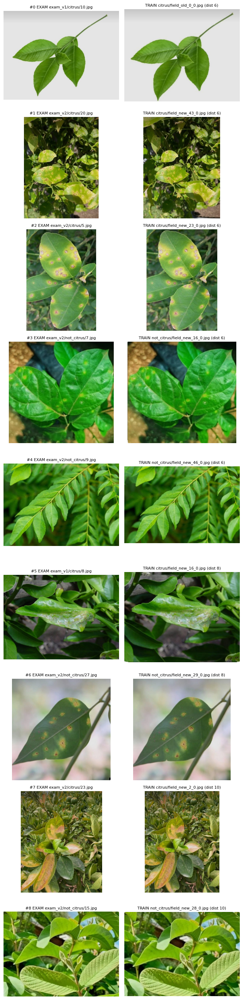